# House Prices — V4
## tl;dr

This version continues the group's V3. It improves feature representation and selects a small,
nonnegative blend. The actual results below are loaded from a completed, reproducible run.
The target remains **RMSE of natural-log prices**. The aim is below **0.110**; the measured result,
including whether that target was reached, is reported explicitly.

In [1]:
from pathlib import Path
import sys,json
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents]
           if (p/'house_prices_v4_pipeline.py').exists()),None)
if ROOT is None:raise FileNotFoundError('Open the notebook inside the DSAI4204 project folder.')
sys.path.insert(0,str(ROOT))
import house_prices_v4_pipeline as v4
FORCE_RETRAIN=False
summary=v4.run_experiment(force=FORCE_RETRAIN)
OUT=v4.OUT
import numpy as np,pandas as pd
from IPython.display import display,Markdown
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.titlesize':13,
                     'axes.spines.top':False,'axes.spines.right':False,'savefig.bbox':'tight'})
FIGURES=OUT/'figures';FIGURES.mkdir(exist_ok=True)
comparison=pd.read_csv(OUT/'comparison.csv')
display(comparison.pivot(index='seed',columns='model',values='log_rmse').round(6))
display(Markdown(f"**Below 0.110 on both recorded splits:** {'Yes' if summary['target_met'] else 'No'}. "
                 f"**Improves the locally reproduced V3 on both:** {'Yes' if summary['improvement_verified'] else 'No'}."))
display(Markdown(summary['selection_note']))

V4 cache verified: matching inputs, recipe, source, versions and output hashes.


model,V3,V4
seed,,
42,0.117905,0.114679
2026,0.115709,0.113709


**Below 0.110 on both recorded splits:** No. **Improves the locally reproduced V3 on both:** Yes.

Candidate preprocessing, model settings and nonnegative weights selected on seed42 OOF; fixed recipe then checked on seed2026. Both remain development/stability results, not an untouched test.

## Context & Methods

V3 used SVR, XGBoost and CatBoost with weights 50/10/40. V4 keeps the same training data,
target and five-fold definitions, but changes the representations and the selected components.

| Change | Implementation |
|---|---|
| A more relevant SVR distance | Absolute feature–target correlations are learned only on the current training fold and used to scale feature distances. |
| Context for location and transaction | Add smoothed target statistics for neighborhood, neighborhood × sale condition, and neighborhood × quality. Training rows exclude their own target from the raw group statistic and global prior; validation uses training tables only. |
| Lower extreme numeric leverage | Learn 99% numeric caps from the training fold for CatBoost; validation rows are retained. |
| Relative house size | Add training-fold neighborhood medians, relative area/quality and area-slope interactions for ElasticNet and a complementary SVR. |
| A compact combination | Select nonnegative weights on seed42 OOF, then freeze them for seed2026. No stacking or Id-specific prediction adjustment. |

### Evaluation meaning

All **1,460** labeled houses receive out-of-fold predictions. No validation houses are deleted.
Imputation, levels, medians, caps, scales and supervised distance statistics are learned from
the corresponding training portion. Raw target statistics for a training row exclude its own label.

The seed42 result is a **development-selection score**, because many candidates and blend weights
were explored using it. Seed2026 is a **stability check**, not an untouched test set. These numbers
are not Kaggle leaderboard scores. No external test-set sale prices are used.

The original V3 notebook saved about 0.117973. Its local reproduction can differ slightly across
software/platform versions. The comparison here uses the locally reproduced V3 and V4 on the
same data and folds. The exploratory records remain under `output/project/v4/search_*`.

In [2]:
weights=pd.read_csv(OUT/'weights.csv')
display(weights.assign(weight_percent=100*weights.weight).round(4))
display(pd.read_csv(OUT/'component_scores.csv').round(6))
print('Training houses:',summary['n_train'],'Test houses:',summary['n_test'])
print('Frozen component configurations:')
for spec in summary['config']['components']:
    print(spec['name'],spec['params'])

,name,weight,weight_percent
0,ContextSVR,0.4749,47.4925
1,ClippedCatBoost,0.2348,23.4833
2,NeighborhoodElasticNet,0.2284,22.8435
3,NeighborhoodSVR,0.0618,6.1807


,name,seed,log_rmse
0,ContextSVR,42,0.116901
1,ClippedCatBoost,42,0.121634
2,NeighborhoodElasticNet,42,0.119826
3,NeighborhoodSVR,42,0.123537
4,ContextSVR,2026,0.116771
5,ClippedCatBoost,2026,0.118360
6,NeighborhoodElasticNet,2026,0.119605
7,NeighborhoodSVR,2026,0.129170


Training houses: 1460 Test houses: 1459
Frozen component configurations:
ContextSVR {'C': 3, 'gamma': 0.0003, 'epsilon': 0.02}
ClippedCatBoost {'iterations': 1800, 'depth': 6, 'learning_rate': 0.03, 'l2_leaf_reg': 5, 'loss_function': 'RMSE', 'random_seed': 42, 'thread_count': 2, 'verbose': False, 'allow_writing_files': False}
NeighborhoodElasticNet {'alpha': 0.0005, 'l1_ratio': 0.9}
NeighborhoodSVR {'C': 10, 'gamma': 0.0001, 'epsilon': 0.01}


## Data & integrity checks

The original CSV files retain literal `"None"` categories. OOF rows, target transformation and test
Id order are checked below. The main program and manifest record the input and code hashes.

In [3]:
train,test,target=v4.h.load_data()
oof={seed:pd.read_csv(OUT/f'oof_seed{seed}.csv') for seed in [42,2026]}
for seed,frame in oof.items():
    assert frame.Id.tolist()==train.Id.tolist()
    assert frame.groupby('fold').size().tolist()==[292]*5
    assert np.allclose(frame.target_log,target,atol=1e-12,rtol=0)
    for name in ['V3','V4']:
        actual=v4.h.rmse(target,frame[name].to_numpy())
        recorded=comparison.loc[comparison.seed.eq(seed)&comparison.model.eq(name),'log_rmse'].iloc[0]
        assert np.isclose(actual,recorded,rtol=0,atol=1e-12)
display(pd.DataFrame({'Dataset':['train','test'],'Rows':[len(train),len(test)],
                      'Columns':[train.shape[1],test.shape[1]]}))

,Dataset,Rows,Columns
0,train,1460,81
1,test,1459,80


## Results
### 1. Compare both recorded splits

Each pair evaluates the same houses using the same seed. Bars start at zero, and the 0.110 line
marks the goal. Improvement percentages describe this experiment, not a guaranteed future reduction.

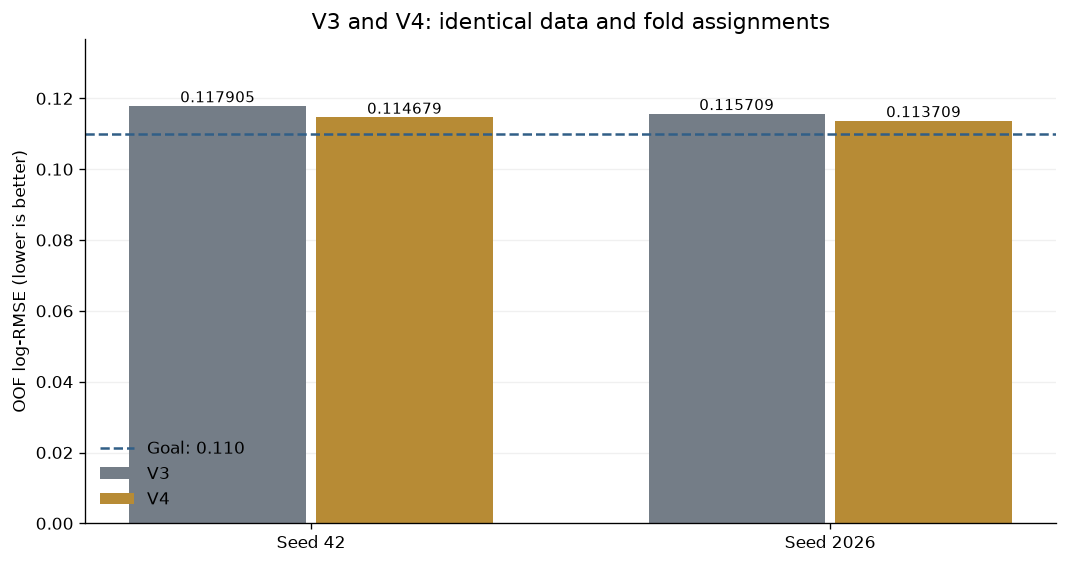

In [4]:
table=comparison.pivot(index='seed',columns='model',values='log_rmse')
x=np.arange(len(table));fig,ax=plt.subplots(figsize=(9,4.8))
for offset,name,color in [(-.18,'V3','#747D87'),(.18,'V4','#B78B35')]:
    bars=ax.bar(x+offset,table[name],.34,label=name,color=color)
    for bar,value in zip(bars,table[name]):
        ax.text(bar.get_x()+bar.get_width()/2,value+.001,f'{value:.6f}',ha='center',fontsize=9)
ax.axhline(.110,color='#315F87',linestyle='--',label='Goal: 0.110')
ax.set_xticks(x,[f'Seed {s}' for s in table.index]);ax.set_ylim(0,table.max().max()*1.16)
ax.set_ylabel('OOF log-RMSE (lower is better)');ax.set_title('V3 and V4: identical data and fold assignments')
ax.legend(frameon=False);ax.grid(axis='y',alpha=.18);ax.set_axisbelow(True)
fig.tight_layout();fig.savefig(FIGURES/'version_comparison.png');plt.show()

### 2. Inspect fold-level variation

Both versions retain every validation row. A version can improve pooled error without improving
every fold. The five folds share training data and should not be treated as independent trials.

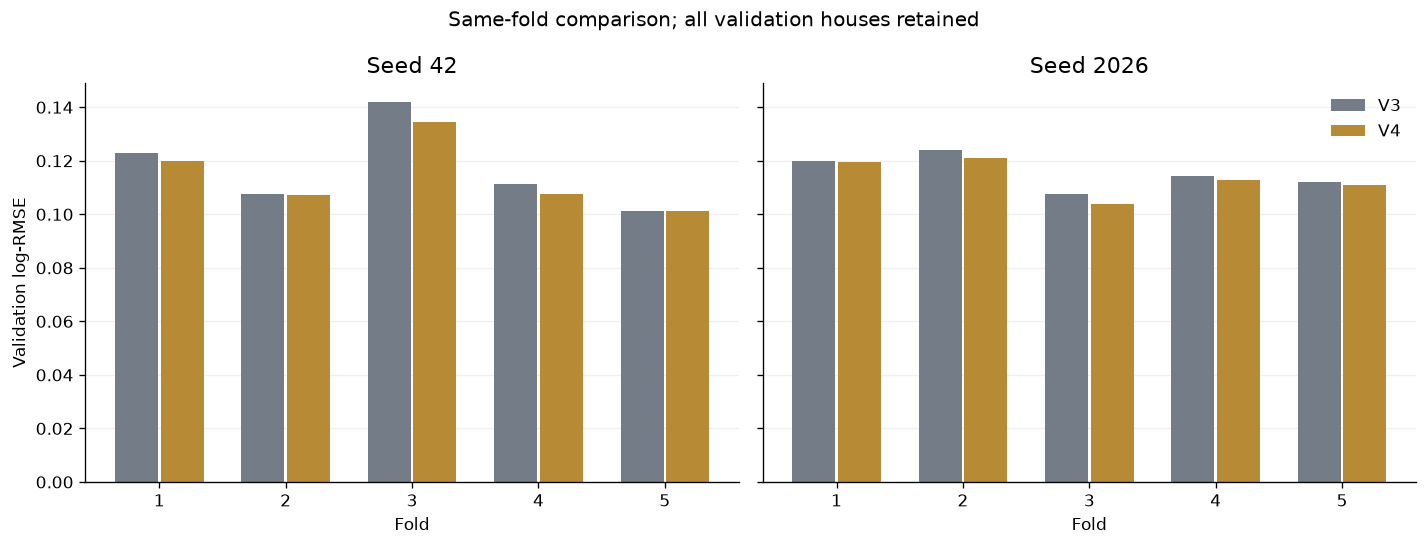

,model,seed,fold,log_rmse,rows
0,V3,42,0,0.122911,292
1,V3,42,1,0.107749,292
2,V3,42,2,0.141952,292
3,V3,42,3,0.111379,292
4,V3,42,4,0.101173,292
5,V4,42,0,0.119967,292
6,V4,42,1,0.107129,292
7,V4,42,2,0.134434,292
8,V4,42,3,0.107444,292
9,V4,42,4,0.101346,292


In [5]:
fold_scores=pd.read_csv(OUT/'fold_scores.csv')
fig,axes=plt.subplots(1,2,figsize=(12,4.6),sharey=True)
for ax,seed in zip(axes,[42,2026]):
    t=fold_scores.loc[fold_scores.seed.eq(seed)].pivot(index='fold',columns='model',values='log_rmse')
    x=np.arange(5)
    ax.bar(x-.18,t.V3,.34,color='#747D87',label='V3')
    ax.bar(x+.18,t.V4,.34,color='#B78B35',label='V4')
    ax.set_xticks(x,[str(i+1) for i in range(5)]);ax.set_xlabel('Fold')
    ax.set_title(f'Seed {seed}');ax.set_ylim(bottom=0);ax.grid(axis='y',alpha=.18);ax.set_axisbelow(True)
axes[0].set_ylabel('Validation log-RMSE');axes[1].legend(frameon=False)
fig.suptitle('Same-fold comparison; all validation houses retained')
fig.tight_layout();fig.savefig(FIGURES/'fold_comparison.png');plt.show()
display(fold_scores.round(6))

### 3. Inspect remaining prediction errors

Residuals use actual minus predicted log price. The hardest houses remain included in the score;
their Id values identify rows for inspection and are never used as model features or patch rules.

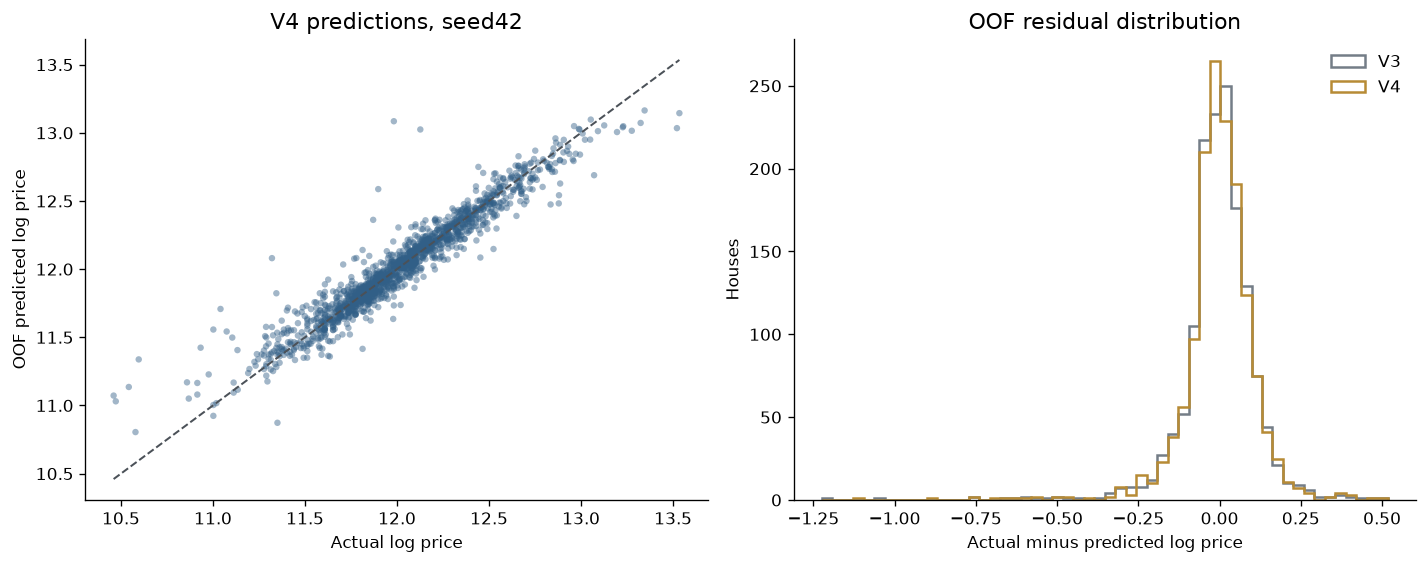

,Id,fold,V3 absolute log error,V4 absolute log error
1298,1299,2,1.22354,1.10197
523,524,2,1.05703,0.89776
632,633,4,0.74704,0.76007
30,31,0,0.76743,0.74119
1324,1325,2,0.64244,0.68887
462,463,1,0.67254,0.66685
495,496,3,0.60277,0.61220
968,969,3,0.60389,0.59280
916,917,0,0.49205,0.55846
410,411,1,0.53353,0.55489


In [6]:
frame=oof[42];actual=frame.target_log.to_numpy();pred=frame.V4.to_numpy()
e3=actual-frame.V3.to_numpy();e4=actual-pred
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
axes[0].scatter(actual,pred,s=15,alpha=.45,color='#315F87',edgecolors='none')
limits=[min(actual.min(),pred.min()),max(actual.max(),pred.max())]
axes[0].plot(limits,limits,'--',color='#4B5158',linewidth=1.2)
axes[0].set(xlabel='Actual log price',ylabel='OOF predicted log price',title='V4 predictions, seed42')
bins=np.linspace(min(e3.min(),e4.min()),max(e3.max(),e4.max()),55)
axes[1].hist(e3,bins=bins,histtype='step',linewidth=1.5,color='#747D87',label='V3')
axes[1].hist(e4,bins=bins,histtype='step',linewidth=1.5,color='#B78B35',label='V4')
axes[1].set(xlabel='Actual minus predicted log price',ylabel='Houses',title='OOF residual distribution')
axes[1].legend(frameon=False);fig.tight_layout();fig.savefig(FIGURES/'prediction_diagnostics.png');plt.show()
hard=frame[['Id','fold']].copy();hard['V3 absolute log error']=np.abs(e3);hard['V4 absolute log error']=np.abs(e4)
display(hard.sort_values('V4 absolute log error',ascending=False).head(10).round(5))

### 4. Read the frozen blend

Weights sum to one and are applied to log-price predictions. Final models are fitted on all labeled
rows. The test predictions are converted back to positive prices using `exp()`.

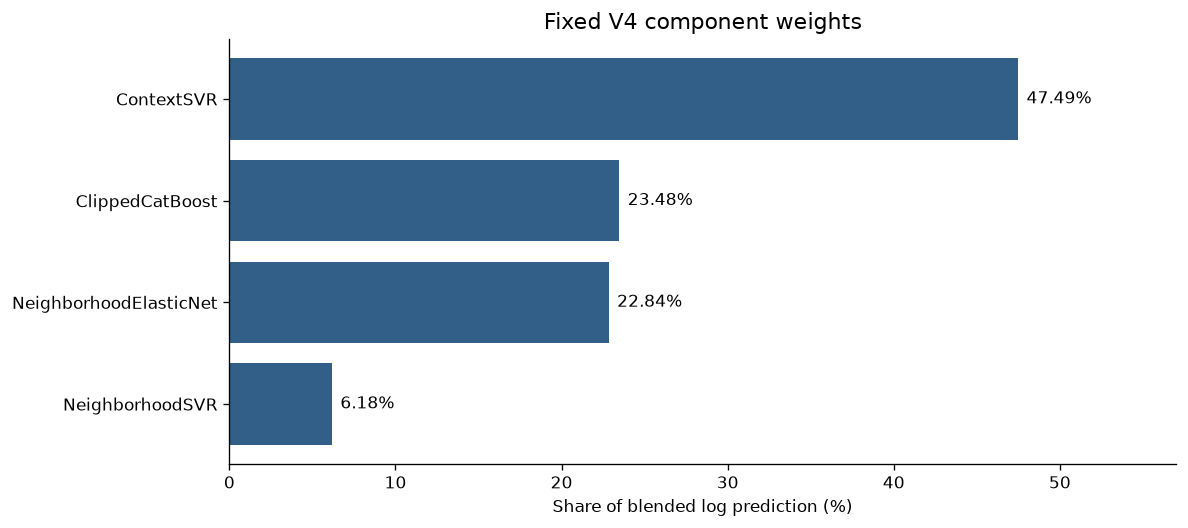

,Id,SalePrice
0,1461,121677.793603
1,1462,162588.037431
2,1463,186666.794240
3,1464,198302.900810
4,1465,189158.001098


Saved: /Users/lewiszhang/Desktop/DSAI4204/submission_v4.csv


In [7]:
fig,ax=plt.subplots(figsize=(10,4.5));t=weights.sort_values('weight')
bars=ax.barh(t.name,t.weight*100,color='#315F87')
for bar,value in zip(bars,t.weight*100):ax.text(value+.5,bar.get_y()+bar.get_height()/2,f'{value:.2f}%',va='center')
ax.set_xlim(0,max(t.weight)*100*1.2);ax.set_xlabel('Share of blended log prediction (%)')
ax.set_title('Fixed V4 component weights');fig.tight_layout();fig.savefig(FIGURES/'blend_weights.png');plt.show()
submission=pd.read_csv(OUT/'submission_v4.csv')
assert submission.Id.tolist()==test.Id.tolist() and len(submission)==1459
assert np.isfinite(submission.SalePrice).all() and (submission.SalePrice>0).all()
display(submission.head());print('Saved:',ROOT/'submission_v4.csv')

## Takeaways

The statement below is computed from the saved run. Both improvements and the remaining gap to
0.110 must be retained in the project report. Neither a lower development score nor a stability
check establishes a leaderboard result.

In [8]:
display(Markdown(
    f"**Seed42:** {summary['v3_seed42']:.6f} → {summary['v4_seed42']:.6f} "
    f"({summary['relative_improvement_seed42']:.2%} lower error).  "
    f"**Seed2026:** {summary['v3_seed2026']:.6f} → {summary['v4_seed2026']:.6f} "
    f"({summary['relative_improvement_seed2026']:.2%} lower error)."))
display(Markdown('**0.110 target:** '+('Reached on both recorded splits.' if summary['target_met']
                 else 'Not reached on both recorded splits. This is an improved candidate, not a claim of meeting the target.')))
print('No Kaggle submission was made; no external test-set prices were used.')

**Seed42:** 0.117905 → 0.114679 (2.74% lower error).  **Seed2026:** 0.115709 → 0.113709 (1.73% lower error).

**0.110 target:** Not reached on both recorded splits. This is an improved candidate, not a claim of meeting the target.

No Kaggle submission was made; no external test-set prices were used.
